# PROJETO DE ANÁLISE DE DADOS - GRUPO 3
## Painel das Escolas do Futuro de Goiás

**Integrantes:** Jacob Almeida, Carlos Henrique, Junio e Jhullyana  
**Tema:** Educação — qualificação profissional oferecida pelas Escolas do Futuro de Goiás.

Este notebook usa a base `dados_tratados.csv`.

## 1. Problema

Não está claro como a oferta de turmas, vagas e matrículas das Escolas do Futuro de Goiás se distribui entre escolas, categorias e cursos, nem se as vagas ofertadas estão sendo preenchidas e como isso mudou ao longo dos anos. Sem essa visão, é difícil avaliar se a oferta de cursos atende à procura.

## 2. Pergunta principal

**Como as turmas, as vagas e as matrículas dos cursos das Escolas do Futuro de Goiás estão distribuídas entre escolas, categorias e cursos, e como isso mudou de 2022 a 2025?**

## 3. Objetivos

### Objetivo geral
Analisar a distribuição das turmas, das vagas e das matrículas dos cursos das Escolas do Futuro de Goiás entre escolas, categorias e cursos, no período de 2022 a 2025.

### Objetivos específicos
1. Identificar a quantidade de turmas, vagas e matrículas por escola, categoria e curso.
2. Comparar a taxa de ocupação das vagas entre escolas e cursos.
3. Identificar os cursos e as escolas com maior e menor número de matrículas.
4. Verificar a evolução do número de turmas e de matrículas ao longo dos anos de 2022 a 2025.
5. Observar a proporção de turmas por status, turno e modalidade.

### Perguntas que serão investigadas
- Qual curso e qual categoria possuem mais matrículas?
- Qual escola possui mais matrículas e qual possui menos?
- Qual é a taxa de ocupação das vagas e onde ela é menor?
- Existe diferença de ocupação entre turnos e modalidades?
- Como o número de turmas e de matrículas mudou ao longo do tempo?
- Qual categoria apresentou maior crescimento no período?

## 4. Importação das bibliotecas

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

## 5. Carregamento dos dados
No Google Colab, envie o arquivo `dados_tratados.csv` na área de arquivos. Se o arquivo estiver na mesma pasta do notebook, o código abaixo funciona diretamente.

In [ ]:
from pathlib import Path

# Carregar a base de dados tratada.
# No computador, o CSV deve estar na mesma pasta do notebook.
caminhos_base = [
    Path("/mnt/data/dados_tratados(1).csv"),
    Path("dados_tratados(1).csv"),
    Path("dados_tratados.csv"),
]

caminho_csv = next((caminho for caminho in caminhos_base if caminho.exists()), None)

if caminho_csv is not None:
    dados = pd.read_csv(caminho_csv, sep=None, engine="python", encoding="utf-8-sig")
else:
    # No Google Colab, permite selecionar o arquivo CSV manualmente.
    try:
        from google.colab import files
        arquivo_enviado = files.upload()
        nome_arquivo = next(iter(arquivo_enviado))
        dados = pd.read_csv(nome_arquivo, sep=None, engine="python", encoding="utf-8-sig")
    except ImportError:
        raise FileNotFoundError(
            "Não encontrei 'dados_tratados(1).csv' nem 'dados_tratados.csv'. "
            "Coloque o arquivo CSV na mesma pasta do notebook."
        )

print("Base carregada:", caminho_csv if caminho_csv is not None else nome_arquivo)
print("Dimensões da base:", dados.shape)
dados.head()

## 6. Conhecendo a base
Vamos verificar o tamanho da base, os nomes das colunas, os tipos de dados e se existem valores vazios.

In [ ]:
print("Quantidade de linhas e colunas:")
print(dados.shape)

print("\\nNomes das colunas:")
print(dados.columns.tolist())

print("\\nTipos de dados:")
print(dados.dtypes)

print("\\nValores vazios por coluna:")
print(dados.isnull().sum())

print("\\nPrimeiras linhas da base:")
display(dados.head())

Quantidade de linhas e colunas:
(3616, 15)
\nNomes das colunas:
['id_turma', 'turma', 'escola', 'projeto', 'categoria', 'curso', 'modalidade', 'qtde_vagas', 'turno', 'data_inicio', 'data_fim', 'status_turma', 'carga_horaria', 'matriculas_turma', 'matriculas_aptas']
\nTipos de dados:
id_turma              int64
turma                object
escola               object
projeto              object
categoria            object
curso                object
modalidade           object
qtde_vagas            int64
turno                object
data_inicio          object
data_fim             object
status_turma         object
carga_horaria       float64
matriculas_turma      int64
matriculas_aptas    float64
dtype: object
\nValores vazios por coluna:
id_turma              0
turma                 0
escola                0
projeto               0
categoria             0
curso                 0
modalidade            0
qtde_vagas            0
turno                 0
data_inicio           0
data_fim     

,id_turma,turma,escola,projeto,categoria,curso,modalidade,qtde_vagas,turno,data_inicio,data_fim,status_turma,carga_horaria,matriculas_turma,matriculas_aptas
0,5575,QP-ABF-PMU-V2-2022,EM ARTES BASILEU FRANÇA,01 - EFGS - ESCOLAS DO FUTURO DO ESTADO DE GOIÁS,Qualificação,PERFORMANCE MUSICAL,PRESENCIAL,23,VESPERTINO,2022-02-14,2024-06-28,Concluído,126.0,23,11.0
1,5535,TEC-ABF-MIM-N1-2022,EM ARTES BASILEU FRANÇA,01 - EFGS - ESCOLAS DO FUTURO DO ESTADO DE GOIÁS,Técnico,TÉCNICO DE NÍVEL MEDIO EM INSTRUMENTO MUSICAL,PRESENCIAL,22,NOTURNO,2020-02-17,2024-06-30,Concluído,267.0,17,11.0
2,5534,TEC-ABF-MIM-V1-2022,EM ARTES BASILEU FRANÇA,01 - EFGS - ESCOLAS DO FUTURO DO ESTADO DE GOIÁS,Técnico,TÉCNICO DE NÍVEL MEDIO EM INSTRUMENTO MUSICAL,PRESENCIAL,22,VESPERTINO,2021-05-26,2024-08-14,Concluído,235.0,17,15.0
3,5472,CP-JLB-MKTDG-ONL-N3-2022,JOSÉ LUIZ BITTENCOURT,01 - EFGS - ESCOLAS DO FUTURO DO ESTADO DE GOIÁS,Capacitação,MARKETING DIGITAL - ONL,PRESENCIAL,34,NOTURNO,2022-06-29,2022-07-13,Concluído,23.0,34,25.0
4,5466,CP-LR-PGIV-ONL-N1-2022,LUIZ RASSI,01 - EFGS - ESCOLAS DO FUTURO DO ESTADO DE GOIÁS,Capacitação,PRODUÇÃO DE GAMES E INTERAÇÃO VIRTUAL - ONL,PRESENCIAL,26,NOTURNO,2022-06-21,2022-07-01,Concluído,16.0,23,14.0


### Preparação dos dados

A base possui as colunas necessárias para analisar escolas, cursos, categorias, vagas, matrículas, turno, modalidade e status. Como o arquivo não apresenta uma coluna chamada `semestre`, vamos usar o ano de `data_inicio` para fazer uma análise anual. O período principal será de 2022 a 2025.

**Atenção:** o ano de início da turma é uma aproximação para a análise temporal. Ele não substitui o semestre de origem dos arquivos.

In [ ]:
# Transformar a data de início em data reconhecida pelo pandas
dados["data_inicio"] = pd.to_datetime(dados["data_inicio"], errors="coerce")

# Garantir que as colunas numéricas estejam como números
colunas_numericas = ["id_turma", "qtde_vagas", "matriculas_turma", "matriculas_aptas"]
for coluna in colunas_numericas:
    dados[coluna] = pd.to_numeric(dados[coluna], errors="coerce")

# Criar uma coluna com o ano de início da turma
dados["ano"] = dados["data_inicio"].dt.year

# Filtrar os anos de 2022 a 2025
dados_periodo = dados[dados["ano"].between(2022, 2025)].copy()

print("Quantidade de registros na base completa:", len(dados))
print("Quantidade de registros entre 2022 e 2025:", len(dados_periodo))
display(dados_periodo.head())

Quantidade de registros na base completa: 3616
Quantidade de registros entre 2022 e 2025: 3125


,id_turma,turma,escola,projeto,categoria,curso,modalidade,qtde_vagas,turno,data_inicio,data_fim,status_turma,carga_horaria,matriculas_turma,matriculas_aptas,ano
0,5575,QP-ABF-PMU-V2-2022,EM ARTES BASILEU FRANÇA,01 - EFGS - ESCOLAS DO FUTURO DO ESTADO DE GOIÁS,Qualificação,PERFORMANCE MUSICAL,PRESENCIAL,23,VESPERTINO,2022-02-14,2024-06-28,Concluído,126.0,23,11.0,2022
3,5472,CP-JLB-MKTDG-ONL-N3-2022,JOSÉ LUIZ BITTENCOURT,01 - EFGS - ESCOLAS DO FUTURO DO ESTADO DE GOIÁS,Capacitação,MARKETING DIGITAL - ONL,PRESENCIAL,34,NOTURNO,2022-06-29,2022-07-13,Concluído,23.0,34,25.0,2022
4,5466,CP-LR-PGIV-ONL-N1-2022,LUIZ RASSI,01 - EFGS - ESCOLAS DO FUTURO DO ESTADO DE GOIÁS,Capacitação,PRODUÇÃO DE GAMES E INTERAÇÃO VIRTUAL - ONL,PRESENCIAL,26,NOTURNO,2022-06-21,2022-07-01,Concluído,16.0,23,14.0,2022
5,5465,CP-SLLKO-LGEPS-ONL-M1-2022,SARAH LUÍSA LEMOS KUBITSCHEK DE OLIVEIRA,01 - EFGS - ESCOLAS DO FUTURO DO ESTADO DE GOIÁS,Capacitação,LIDERANÇA E GESTÃO DE EQUIPES - ONL,PRESENCIAL,26,MATUTINO,2022-06-16,2022-06-30,Concluído,12.0,18,7.0,2022
6,5464,CP-SLLKO-GF-ONL-V1-2022,SARAH LUÍSA LEMOS KUBITSCHEK DE OLIVEIRA,01 - EFGS - ESCOLAS DO FUTURO DO ESTADO DE GOIÁS,Capacitação,GESTÃO FINANCEIRA - ONL,PRESENCIAL,39,VESPERTINO,2022-06-16,2022-06-30,Concluído,25.0,37,13.0,2022


## 7. Análise 1 — Qual curso e categoria possuem mais matrículas?

**Pergunta:** Quais cursos e categorias concentram a maior quantidade de matrículas?

Vamos somar as matrículas por curso e por categoria e mostrar os cinco primeiros resultados.

In [ ]:
# Matrículas por curso
matriculas_curso = (
    dados_periodo.groupby("curso")["matriculas_turma"]
    .sum()
    .sort_values(ascending=False)
)

print("Cinco cursos com mais matrículas:")
display(matriculas_curso.head(5))

# Matrículas por categoria
matriculas_categoria = (
    dados_periodo.groupby("categoria")["matriculas_turma"]
    .sum()
    .sort_values(ascending=False)
)

print("Matrículas por categoria:")
display(matriculas_categoria)

Cinco cursos com mais matrículas:


curso
PACOTE OFFICE                                           2594
PILOTAGEM DE DRONE (VANT)                               2577
SUPERIOR DE TECNOLOGIA EM PRODUÇÃO CÊNICA               1673
MARKETING DIGITAL                                       1570
TÉCNICO DE NÍVEL MÉDIO EM MARKETING E MÍDIAS SOCIAIS    1568
Name: matriculas_turma, dtype: int64

Matrículas por categoria:


categoria
Qualificação    28399
Capacitação     27091
Técnico          8921
Graduação        1681
Name: matriculas_turma, dtype: int64

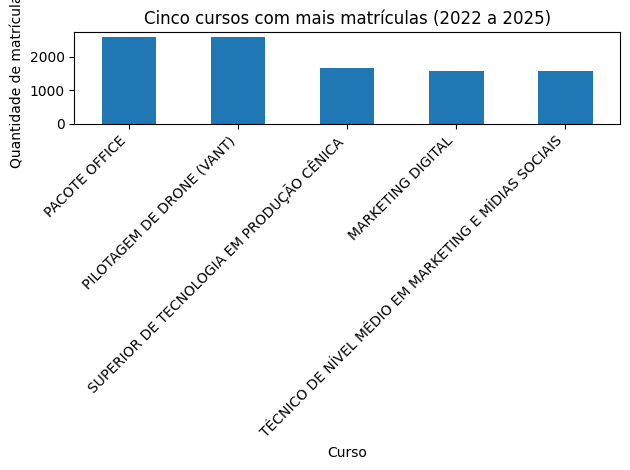

In [ ]:
matriculas_curso.head(5).plot(kind="bar")
plt.title("Cinco cursos com mais matrículas (2022 a 2025)")
plt.xlabel("Curso")
plt.ylabel("Quantidade de matrículas")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Interpretação:** observe o primeiro curso da tabela para identificar o curso com mais matrículas. A tabela de categorias mostra qual categoria reúne mais matrículas.

**Próxima pergunta:** os cursos com mais matrículas também possuem maior ocupação das vagas?

## 8. Análise 2 — Qual escola possui mais e menos matrículas?

**Pergunta:** Como as matrículas estão distribuídas entre as escolas?

In [ ]:
matriculas_escola = (
    dados_periodo.groupby("escola")["matriculas_turma"]
    .sum()
    .sort_values(ascending=False)
)

print("Cinco escolas com mais matrículas:")
display(matriculas_escola.head(5))

print("Cinco escolas com menos matrículas:")
display(matriculas_escola.tail(5))

Cinco escolas com mais matrículas:


escola
EM ARTES BASILEU FRANÇA                     30177
LUIZ RASSI                                  10322
SARAH LUÍSA LEMOS KUBITSCHEK DE OLIVEIRA     9645
JOSÉ LUIZ BITTENCOURT                        8319
PAULO RENATO DE SOUZA                        4061
Name: matriculas_turma, dtype: int64

Cinco escolas com menos matrículas:


escola
JOSÉ LUIZ BITTENCOURT                  8319
PAULO RENATO DE SOUZA                  4061
RAUL BRANDÃO DE CASTRO                 2812
UDEPI ST NOVO MUNDO - OVG GYN (ABF)     444
UDEPI JARAGUÁ (ABF)                     312
Name: matriculas_turma, dtype: int64

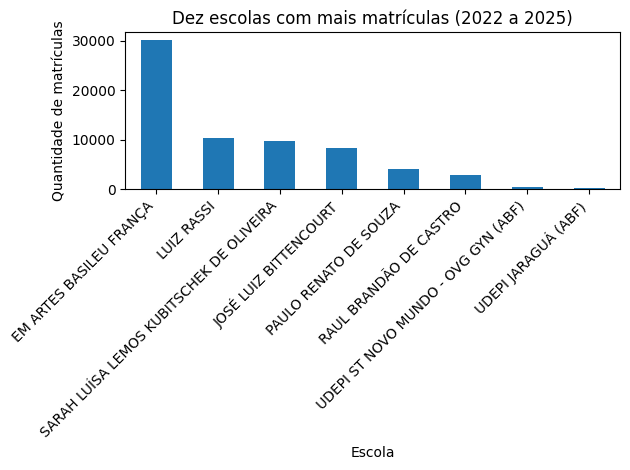

In [ ]:
matriculas_escola.head(10).plot(kind="bar")
plt.title("Dez escolas com mais matrículas (2022 a 2025)")
plt.xlabel("Escola")
plt.ylabel("Quantidade de matrículas")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Interpretação:** a primeira linha da tabela indica a escola com mais matrículas. As últimas linhas mostram as escolas com os menores totais dentro da lista ordenada.

**Próxima pergunta:** as escolas com menos matrículas também oferecem menos vagas ou têm menor ocupação?

## 9. Análise 3 — Qual é a taxa de ocupação das vagas?

**Pergunta:** Qual é a relação entre o total de matrículas e o total de vagas? Em quais cursos a ocupação é menor?

A taxa será calculada assim: total de matrículas dividido pelo total de vagas, multiplicado por 100.

In [ ]:
total_vagas = dados_periodo["qtde_vagas"].sum()
total_matriculas = dados_periodo["matriculas_turma"].sum()

if total_vagas > 0:
    taxa_ocupacao = total_matriculas / total_vagas * 100
else:
    taxa_ocupacao = 0

print("Total de vagas:", total_vagas)
print("Total de matrículas:", total_matriculas)
print(f"Taxa geral de ocupação: {taxa_ocupacao:.2f}%")

# Calcular ocupação por curso usando as somas, evitando calcular a média de percentuais
ocupacao_curso = dados_periodo.groupby("curso").agg(
    vagas=("qtde_vagas", "sum"),
    matriculas=("matriculas_turma", "sum")
)

ocupacao_curso["taxa_ocupacao_%"] = (
    ocupacao_curso["matriculas"] / ocupacao_curso["vagas"] * 100
)

print("Cursos com menor taxa de ocupação (considerando cursos com vagas):")
display(
    ocupacao_curso[ocupacao_curso["vagas"] > 0]
    .sort_values("taxa_ocupacao_%")
    .head(5)
)

print("Cursos com maior taxa de ocupação:")
display(
    ocupacao_curso[ocupacao_curso["vagas"] > 0]
    .sort_values("taxa_ocupacao_%", ascending=False)
    .head(5)
)

Total de vagas: 70543
Total de matrículas: 66092
Taxa geral de ocupação: 93.69%
Cursos com menor taxa de ocupação (considerando cursos com vagas):


,vagas,matriculas,taxa_ocupacao_%
curso,,,
SUPERIOR DE TECNOLOGIA EM PRODUÇÃO CENICA,250,0,0.0
CAMERATA DE VIOLONCELO,18,0,0.0
ESCRITA DE RESUMOS,20,0,0.0
ESCADA LIVRE 3,1,0,0.0
CIRCO INFANTO ETAPA II,20,0,0.0


Cursos com maior taxa de ocupação:


,vagas,matriculas,taxa_ocupacao_%
curso,,,
SUPERIOR EM PRODUÇÃO CÊNICA REOFERTA,4,8,200.000000
ACROBACIA DE SOLO IV,12,16,133.333333
SUPERIOR DE TECNOLOGIA EM PRODUÇÃO CÊNICA,1368,1673,122.295322
MACRAMÊ II - DECORAÇÃO COM MANDALAS FOLHAS E PENAS EM MACRAMÊ,30,36,120.000000
BORDADO TRADICIONAL I,20,24,120.000000


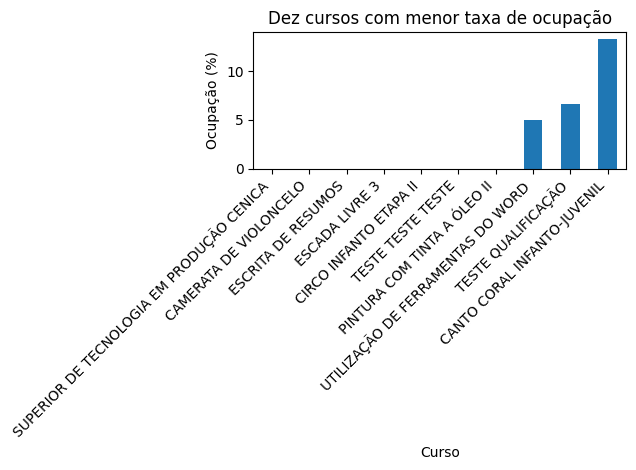

In [ ]:
ocupacao_grafico = (
    ocupacao_curso[ocupacao_curso["vagas"] > 0]
    .sort_values("taxa_ocupacao_%")
    .head(10)
)

ocupacao_grafico["taxa_ocupacao_%"].plot(kind="bar")
plt.title("Dez cursos com menor taxa de ocupação")
plt.xlabel("Curso")
plt.ylabel("Ocupação (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Interpretação:** uma taxa de 100% significa que o número de matrículas é igual ao número de vagas. Valores abaixo de 100% indicam que as matrículas somadas são menores que as vagas somadas.

**Próxima pergunta:** a ocupação muda de acordo com o turno e a modalidade?

## 10. Análise 4 — Existe diferença entre turnos e modalidades?

**Pergunta:** Como as vagas e matrículas se distribuem por turno e modalidade? Qual é a taxa de ocupação em cada grupo?

In [ ]:
ocupacao_turno = dados_periodo.groupby("turno").agg(
    vagas=("qtde_vagas", "sum"),
    matriculas=("matriculas_turma", "sum"),
    turmas=("id_turma", "nunique")
)
ocupacao_turno["taxa_ocupacao_%"] = ocupacao_turno["matriculas"] / ocupacao_turno["vagas"] * 100

print("Resultado por turno:")
display(ocupacao_turno.sort_values("taxa_ocupacao_%", ascending=False))

ocupacao_modalidade = dados_periodo.groupby("modalidade").agg(
    vagas=("qtde_vagas", "sum"),
    matriculas=("matriculas_turma", "sum"),
    turmas=("id_turma", "nunique")
)
ocupacao_modalidade["taxa_ocupacao_%"] = ocupacao_modalidade["matriculas"] / ocupacao_modalidade["vagas"] * 100

print("Resultado por modalidade:")
display(ocupacao_modalidade.sort_values("taxa_ocupacao_%", ascending=False))

Resultado por turno:


,vagas,matriculas,turmas,taxa_ocupacao_%
turno,,,,
NOTURNO,30615,29920,777,97.729871
INTEGRAL,7664,7440,127,97.077244
VESPERTINO,21481,19262,623,89.669941
MATUTINO,10783,9470,381,87.823426


Resultado por modalidade:


,vagas,matriculas,turmas,taxa_ocupacao_%
modalidade,,,,
EAD,5142,5020,64,97.627382
PRESENCIAL,65401,61072,1844,93.380835


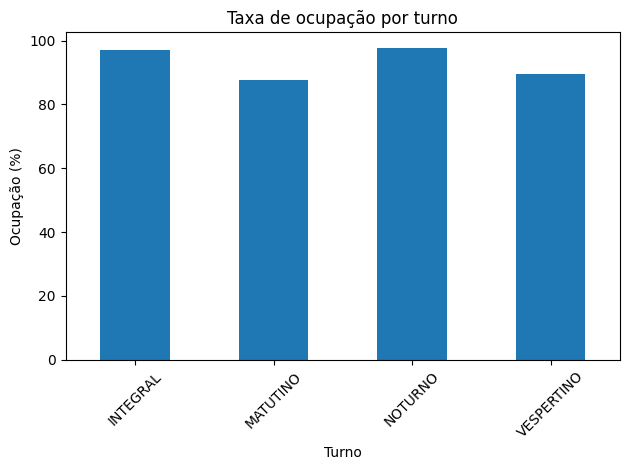

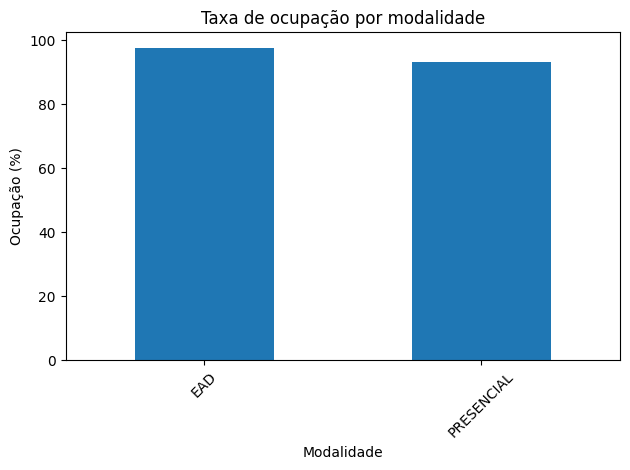

In [ ]:
ocupacao_turno["taxa_ocupacao_%"].plot(kind="bar")
plt.title("Taxa de ocupação por turno")
plt.xlabel("Turno")
plt.ylabel("Ocupação (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

ocupacao_modalidade["taxa_ocupacao_%"].plot(kind="bar")
plt.title("Taxa de ocupação por modalidade")
plt.xlabel("Modalidade")
plt.ylabel("Ocupação (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Interpretação:** compare as taxas calculadas nas tabelas. O turno ou a modalidade com maior percentual apresenta maior ocupação relativa das vagas.

**Próxima pergunta:** o número de turmas e matrículas cresceu ou diminuiu entre 2022 e 2025?

## 11. Análise 5 — Como turmas e matrículas mudaram ao longo dos anos?

**Pergunta:** Como variaram a quantidade de turmas, vagas e matrículas por ano? Qual categoria apresentou maior crescimento de matrículas entre 2022 e 2025?

In [ ]:
resumo_ano = dados_periodo.groupby("ano").agg(
    turmas=("id_turma", "nunique"),
    vagas=("qtde_vagas", "sum"),
    matriculas=("matriculas_turma", "sum")
).sort_index()

print("Turmas, vagas e matrículas por ano:")
display(resumo_ano)

Turmas, vagas e matrículas por ano:


,turmas,vagas,matriculas
ano,,,
2022,524,19644,17154
2023,596,21483,20546
2024,299,13086,12465
2025,489,16330,15927


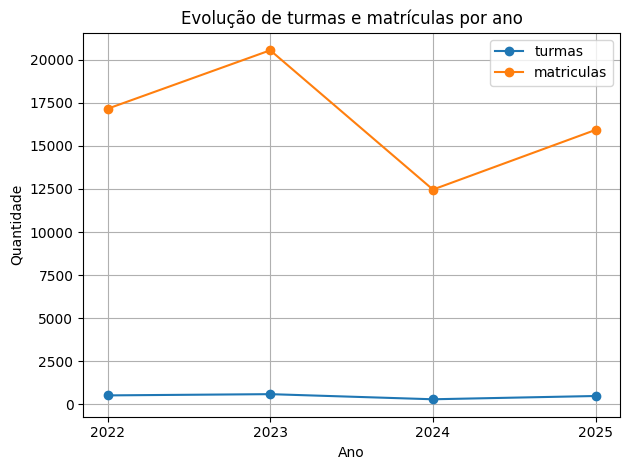

In [ ]:
resumo_ano[["turmas", "matriculas"]].plot(kind="line", marker="o")
plt.title("Evolução de turmas e matrículas por ano")
plt.xlabel("Ano")
plt.ylabel("Quantidade")
plt.xticks(resumo_ano.index)
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# Comparar matrículas por categoria entre o primeiro e o último ano do período
matriculas_categoria_ano = dados_periodo.pivot_table(
    index="categoria",
    columns="ano",
    values="matriculas_turma",
    aggfunc="sum",
    fill_value=0
)

display(matriculas_categoria_ano)

if 2022 in matriculas_categoria_ano.columns and 2025 in matriculas_categoria_ano.columns:
    matriculas_categoria_ano["crescimento_matriculas"] = (
        matriculas_categoria_ano[2025] - matriculas_categoria_ano[2022]
    )
    print("Categorias ordenadas pelo crescimento em número de matrículas (2022 a 2025):")
    display(matriculas_categoria_ano.sort_values("crescimento_matriculas", ascending=False))
else:
    print("Não foi possível comparar 2022 e 2025. Confira se os dois anos existem nos dados filtrados.")

ano,2022,2023,2024,2025
categoria,,,,
Capacitação,6046,8466,4456,8123
Graduação,383,678,384,236
Qualificação,8871,7744,5804,5980
Técnico,1854,3658,1821,1588


Categorias ordenadas pelo crescimento em número de matrículas (2022 a 2025):


ano,2022,2023,2024,2025,crescimento_matriculas
categoria,,,,,
Capacitação,6046,8466,4456,8123,2077
Graduação,383,678,384,236,-147
Técnico,1854,3658,1821,1588,-266
Qualificação,8871,7744,5804,5980,-2891


**Interpretação:** observe se a linha de matrículas sobe ou desce com o passar dos anos. Na tabela por categoria, o maior valor em `crescimento_matriculas` representa o maior aumento absoluto de matrículas entre 2022 e 2025. Um valor negativo indica redução.

**Limitação:** esta análise usa o ano extraído de `data_inicio`, porque o CSV fornecido não possui a coluna `semestre` descrita no planejamento.

## 12. Gráficos exploratórios
Além dos gráficos das análises anteriores, vamos observar a distribuição das turmas por status e por categoria.

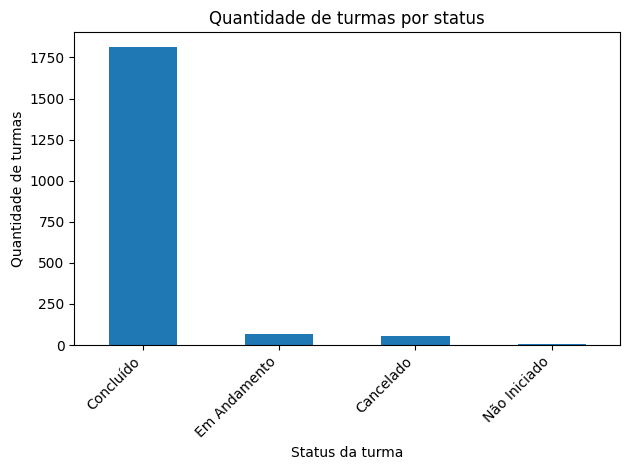

status_turma
Concluído       1812
Em Andamento      66
Cancelado         57
Não Iniciado       5
Name: id_turma, dtype: int64

In [ ]:
# Quantidade de turmas por status
turmas_status = dados_periodo.groupby("status_turma")["id_turma"].nunique().sort_values(ascending=False)

turmas_status.plot(kind="bar")
plt.title("Quantidade de turmas por status")
plt.xlabel("Status da turma")
plt.ylabel("Quantidade de turmas")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

display(turmas_status)

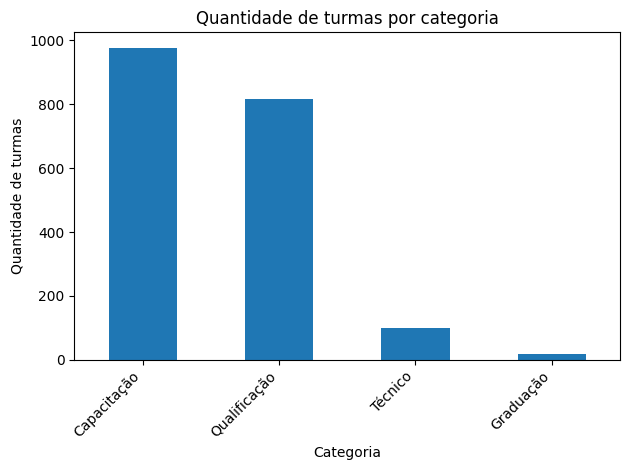

categoria
Capacitação     976
Qualificação    816
Técnico          99
Graduação        17
Name: id_turma, dtype: int64

In [ ]:
# Quantidade de turmas por categoria
turmas_categoria = dados_periodo.groupby("categoria")["id_turma"].nunique().sort_values(ascending=False)

turmas_categoria.plot(kind="bar")
plt.title("Quantidade de turmas por categoria")
plt.xlabel("Categoria")
plt.ylabel("Quantidade de turmas")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

display(turmas_categoria)

## 13. Principais descobertas

Execute as células e use os resultados para completar este resumo. O código abaixo apresenta automaticamente alguns dos principais números calculados na base.

In [ ]:
if len(dados_periodo) > 0:
    curso_maior = matriculas_curso.index[0] if len(matriculas_curso) else "Não identificado"
    escola_maior = matriculas_escola.index[0] if len(matriculas_escola) else "Não identificada"
    categoria_maior = matriculas_categoria.index[0] if len(matriculas_categoria) else "Não identificada"

    print("PRINCIPAIS DESCOBERTAS")
    print("----------------------")
    print(f"Registros analisados de 2022 a 2025: {len(dados_periodo)}")
    print(f"Total de turmas únicas: {dados_periodo['id_turma'].nunique()}")
    print(f"Total de vagas: {total_vagas}")
    print(f"Total de matrículas: {total_matriculas}")
    print(f"Taxa geral de ocupação: {taxa_ocupacao:.2f}%")
    print(f"Curso com mais matrículas: {curso_maior}")
    print(f"Escola com mais matrículas: {escola_maior}")
    print(f"Categoria com mais matrículas: {categoria_maior}")
else:
    print("Não há registros no período de 2022 a 2025. Confira a coluna data_inicio.")

PRINCIPAIS DESCOBERTAS
----------------------
Registros analisados de 2022 a 2025: 3125
Total de turmas únicas: 1908
Total de vagas: 70543
Total de matrículas: 66092
Taxa geral de ocupação: 93.69%
Curso com mais matrículas: PACOTE OFFICE
Escola com mais matrículas: EM ARTES BASILEU FRANÇA
Categoria com mais matrículas: Qualificação


## 14. Primeiros insights

Os insights são interpretações iniciais dos resultados, não conclusões definitivas.

1. **Oferta e procura:**
 Comparar o total de vagas com o total de matrículas ajuda a perceber se a oferta está sendo preenchida.  

2. **Cursos mais procurados:**
Os cursos com mais matrículas podem ajudar a identificar áreas de maior procura.

3. **Diferenças entre escolas:**
Comparar os totais por escola pode indicar onde há maior volume de matrículas; isso não significa, por si só, melhor desempenho, pois a quantidade de vagas também pode ser diferente.

4. **Turno e modalidade:**
Diferenças nas taxas de ocupação podem ajudar a levantar perguntas para uma investigação futura.

5. **Mudança ao longo do tempo:** a comparação de 2022 com 2025 mostra a variação anual dos registros de início de turma, usando `data_inicio` como referência temporal.

**Conclusão inicial:** os resultados deste notebook ajudam a organizar uma primeira visão da oferta de turmas, vagas e matrículas das Escolas do Futuro de Goiás.

# AULA 6 — DOS RESULTADOS AOS INSIGHTS
## Resolução dos itens 25 a 30 e 32

Este notebook complementa a análise exploratória da Aula 5. Execute as células em ordem, depois de carregar o arquivo `dados_tratados.csv` na primeira parte do notebook.

**Período principal:** 2022 a 2025, conforme o notebook da Aula 5. Os resultados são calculados a partir da base carregada, para que possam ser conferidos e atualizados automaticamente.

## Preparação para as análises da Aula 6

A célula abaixo verifica se as colunas necessárias existem e prepara tabelas agregadas. Ela usa as variáveis `dados` e `dados_periodo` já criadas na Aula 5.

In [ ]:
# Conferir as colunas necessárias antes de iniciar
colunas_necessarias = [
    "escola", "curso", "modalidade", "ano",
    "qtde_vagas", "matriculas_turma"
]
faltantes = [c for c in colunas_necessarias if c not in dados_periodo.columns]

if faltantes:
    raise ValueError(
        "Faltam colunas necessárias na base: " + ", ".join(faltantes)
    )

# Garantir que os campos numéricos sejam numéricos
for coluna in ["qtde_vagas", "matriculas_turma"]:
    dados_periodo[coluna] = pd.to_numeric(dados_periodo[coluna], errors="coerce")

# Tratar valores numéricos ausentes como zero apenas para somas agregadas.
# Os valores ausentes originais continuam sendo contabilizados na seção de limitações.
dados_periodo["qtde_vagas"] = dados_periodo["qtde_vagas"].fillna(0)
dados_periodo["matriculas_turma"] = dados_periodo["matriculas_turma"].fillna(0)

print(f"Registros analisados: {len(dados_periodo):,}")
print(f"Período encontrado: {int(dados_periodo['ano'].min())} a {int(dados_periodo['ano'].max())}")

Registros analisados: 3,125
Período encontrado: 2022 a 2025


## 25. Matriz de insights — cinco análises

A matriz reúne cinco resultados, as evidências, a interpretação e a relevância de cada análise. Os resultados numéricos são calculados diretamente da base.

In [ ]:
# 1. Matrículas por escola
matriculas_escola_a6 = (
    dados_periodo.groupby("escola")["matriculas_turma"]
    .sum().sort_values(ascending=False)
)
escolas_validas = matriculas_escola_a6[matriculas_escola_a6.index.notna()]

if len(escolas_validas) >= 2:
    escola1, valor1 = escolas_validas.index[0], float(escolas_validas.iloc[0])
    escola2, valor2 = escolas_validas.index[1], float(escolas_validas.iloc[1])
    diferenca_escolas = valor1 - valor2
    diferenca_pct = (diferenca_escolas / valor2 * 100) if valor2 else float("nan")
else:
    escola1, valor1, escola2, valor2 = "Não identificado", 0, "Não identificado", 0
    diferenca_escolas, diferenca_pct = 0, float("nan")

# 2. Matrículas por ano
matriculas_ano_a6 = dados_periodo.groupby("ano")["matriculas_turma"].sum().sort_index()
variacao_ano = matriculas_ano_a6.pct_change() * 100

# 3. Ocupação por modalidade
ocupacao_modalidade_a6 = dados_periodo.groupby("modalidade", dropna=False).agg(
    vagas=("qtde_vagas", "sum"),
    matriculas=("matriculas_turma", "sum")
)
ocupacao_modalidade_a6["ocupacao_pct"] = (
    ocupacao_modalidade_a6["matriculas"] /
    ocupacao_modalidade_a6["vagas"].replace(0, float("nan")) * 100
)
ocupacao_modalidade_validas = ocupacao_modalidade_a6.dropna(subset=["ocupacao_pct"]).sort_values("ocupacao_pct", ascending=False)

# 4. Matrículas por curso
matriculas_curso_a6 = (
    dados_periodo.groupby("curso")["matriculas_turma"]
    .sum().sort_values(ascending=False)
)
curso_top = matriculas_curso_a6.index[0] if len(matriculas_curso_a6) else "Não identificado"
curso_top_valor = float(matriculas_curso_a6.iloc[0]) if len(matriculas_curso_a6) else 0

# 5. Vagas versus matrículas
total_vagas_a6 = float(dados_periodo["qtde_vagas"].sum())
total_matriculas_a6 = float(dados_periodo["matriculas_turma"].sum())
ocupacao_geral_a6 = total_matriculas_a6 / total_vagas_a6 * 100 if total_vagas_a6 else float("nan")

matriz_insights = pd.DataFrame([
    {
        "Nº": 1,
        "Pergunta": "Qual escola concentra mais matrículas?",
        "Resultado": f"{escola1}: {valor1:,.0f}; segunda: {escola2}: {valor2:,.0f}; diferença: {diferenca_escolas:,.0f} ({diferenca_pct:.2f}%).",
        "Evidência": "Soma de matriculas_turma agrupada por escola; gráfico de barras.",
        "Interpretação": "A escola líder possui maior volume de matrículas que a segunda colocada.",
        "Insight": "Existe concentração de matrículas em determinadas escolas.",
        "Relevância": "Alta"
    },
    {
        "Nº": 2,
        "Pergunta": "Como as matrículas evoluíram por ano?",
        "Resultado": "; ".join([f"{int(a)}: {v:,.0f}" for a, v in matriculas_ano_a6.items()]) or "Sem dados anuais.",
        "Evidência": "Soma anual de matriculas_turma e gráfico de linha.",
        "Interpretação": "A série anual permite identificar crescimento e redução.",
        "Insight": "As matrículas variam ao longo do período e as mudanças devem ser investigadas.",
        "Relevância": "Alta"
    },
    {
        "Nº": 3,
        "Pergunta": "A ocupação das vagas varia por modalidade?",
        "Resultado": "; ".join([f"{idx}: {row['ocupacao_pct']:.2f}%" for idx, row in ocupacao_modalidade_validas.iterrows()]) or "Sem dados suficientes para calcular.",
        "Evidência": "Soma de vagas e matrículas por modalidade e cálculo de ocupação.",
        "Interpretação": "As modalidades podem apresentar percentuais diferentes de preenchimento.",
        "Insight": "O aproveitamento das vagas deve ser acompanhado por modalidade.",
        "Relevância": "Alta"
    },
    {
        "Nº": 4,
        "Pergunta": "Qual curso tem mais matrículas?",
        "Resultado": f"{curso_top}: {curso_top_valor:,.0f} matrículas.",
        "Evidência": "Soma de matriculas_turma agrupada por curso; gráfico de barras.",
        "Interpretação": "O curso líder reúne o maior volume de matrículas na base.",
        "Insight": "A distribuição das matrículas varia entre os cursos.",
        "Relevância": "Média"
    },
    {
        "Nº": 5,
        "Pergunta": "Como o total de vagas se compara ao total de matrículas?",
        "Resultado": f"{total_vagas_a6:,.0f} vagas; {total_matriculas_a6:,.0f} matrículas; ocupação geral: {ocupacao_geral_a6:.2f}%.",
        "Evidência": "Soma de qtde_vagas e matriculas_turma e cálculo do percentual de ocupação.",
        "Interpretação": "O total de matrículas é comparado com a capacidade ofertada em vagas.",
        "Insight": "É importante localizar cursos e turmas com vagas não preenchidas.",
        "Relevância": "Alta"
    }
])

display(matriz_insights)

,Nº,Pergunta,Resultado,Evidência,Interpretação,Insight,Relevância
0,1,Qual escola concentra mais matrículas?,"EM ARTES BASILEU FRANÇA: 30,177; segunda: LUIZ...",Soma de matriculas_turma agrupada por escola; ...,A escola líder possui maior volume de matrícul...,Existe concentração de matrículas em determina...,Alta
1,2,Como as matrículas evoluíram por ano?,"2022: 17,154; 2023: 20,546; 2024: 12,465; 2025...",Soma anual de matriculas_turma e gráfico de li...,A série anual permite identificar crescimento ...,As matrículas variam ao longo do período e as ...,Alta
2,3,A ocupação das vagas varia por modalidade?,EAD: 97.63%; PRESENCIAL: 93.38%,Soma de vagas e matrículas por modalidade e cá...,As modalidades podem apresentar percentuais di...,O aproveitamento das vagas deve ser acompanhad...,Alta
3,4,Qual curso tem mais matrículas?,"PACOTE OFFICE: 2,594 matrículas.",Soma de matriculas_turma agrupada por curso; g...,O curso líder reúne o maior volume de matrícul...,A distribuição das matrículas varia entre os c...,Média
4,5,Como o total de vagas se compara ao total de m...,"70,543 vagas; 66,092 matrículas; ocupação gera...",Soma de qtde_vagas e matriculas_turma e cálcul...,O total de matrículas é comparado com a capaci...,É importante localizar cursos e turmas com vag...,Alta


## 26. Escolha dos três principais insights

A pontuação abaixo é uma avaliação qualitativa da equipe com base nos seis critérios da atividade. Pode ser alterada caso a análise dos dados mostre que outro insight é mais relevante.

In [ ]:
criterios = [
    "Responde ao problema",
    "Tem evidência nos dados",
    "É relevante",
    "É explicado claramente",
    "Pode gerar recomendação",
    "Pode virar visualização"
]

avaliacao = pd.DataFrame([
    ["Concentração de matrículas por escola", 1, 1, 1, 1, 1, 1],
    ["Evolução anual das matrículas",          1, 1, 1, 1, 1, 1],
    ["Ocupação por modalidade",                1, 1, 1, 1, 1, 1],
    ["Concentração por curso",                 1, 1, 1, 1, 1, 1],
    ["Relação entre vagas e matrículas",       1, 1, 1, 1, 0, 1],
], columns=["Insight"] + criterios)

avaliacao["Pontuação"] = avaliacao[criterios].sum(axis=1)
avaliacao["Resultado"] = avaliacao["Pontuação"].map(lambda x: f"{x}/6")
display(avaliacao.sort_values("Pontuação", ascending=False))

print(
    "Seleção sugerida: concentração por escola, evolução anual e ocupação por modalidade. "
    "A avaliação deve ser confirmada pela equipe com base nos resultados observados."
)

,Insight,Responde ao problema,Tem evidência nos dados,É relevante,É explicado claramente,Pode gerar recomendação,Pode virar visualização,Pontuação,Resultado
0,Concentração de matrículas por escola,1,1,1,1,1,1,6,6/6
1,Evolução anual das matrículas,1,1,1,1,1,1,6,6/6
2,Ocupação por modalidade,1,1,1,1,1,1,6,6/6
3,Concentração por curso,1,1,1,1,1,1,6,6/6
4,Relação entre vagas e matrículas,1,1,1,1,0,1,5,5/6


Seleção sugerida: concentração por escola, evolução anual e ocupação por modalidade. A avaliação deve ser confirmada pela equipe com base nos resultados observados.


## 27. Do resultado ao insight — aprofundamento

Para cada resultado, a equipe registra uma pergunta nova. Quando a base não contém os dados necessários, isso é registrado como limitação, sem inventar uma resposta.

In [ ]:
perguntas_novas = pd.DataFrame([
    {
        "Descoberta": "Uma escola possui mais matrículas que as demais.",
        "Nova pergunta": "Ela oferece mais turmas e vagas ou possui maior procura por turma?",
        "A base permite responder?": "Parcialmente. É possível comparar turmas e vagas; não há dados de população ou procura potencial."
    },
    {
        "Descoberta": "As matrículas variam entre os anos.",
        "Nova pergunta": "Quais escolas e cursos contribuíram para o crescimento ou a redução?",
        "A base permite responder?": "Sim, por meio de agrupamentos adicionais por ano, escola e curso; não explica sozinha as causas."
    },
    {
        "Descoberta": "A ocupação varia entre modalidades.",
        "Nova pergunta": "A diferença aparece em todas as escolas ou apenas em algumas?",
        "A base permite responder?": "Sim, se houver registros suficientes por escola e modalidade."
    },
    {
        "Descoberta": "Alguns cursos concentram mais matrículas.",
        "Nova pergunta": "Os cursos com mais matrículas também são os que oferecem mais turmas e vagas?",
        "A base permite responder?": "Sim, comparando turmas, vagas e matrículas por curso."
    },
    {
        "Descoberta": "Vagas e matrículas podem estar relacionadas.",
        "Nova pergunta": "Turmas com mais vagas apresentam menor percentual de ocupação?",
        "A base permite responder?": "É possível investigar a associação, mas associação não comprova causalidade."
    }
])
display(perguntas_novas)

,Descoberta,Nova pergunta,A base permite responder?
0,Uma escola possui mais matrículas que as demais.,Ela oferece mais turmas e vagas ou possui maio...,Parcialmente. É possível comparar turmas e vag...
1,As matrículas variam entre os anos.,Quais escolas e cursos contribuíram para o cre...,"Sim, por meio de agrupamentos adicionais por a..."
2,A ocupação varia entre modalidades.,A diferença aparece em todas as escolas ou ape...,"Sim, se houver registros suficientes por escol..."
3,Alguns cursos concentram mais matrículas.,Os cursos com mais matrículas também são os qu...,"Sim, comparando turmas, vagas e matrículas por..."
4,Vagas e matrículas podem estar relacionadas.,Turmas com mais vagas apresentam menor percent...,"É possível investigar a associação, mas associ..."


## 28. Etapa 5 — Validar com Python

O código compara quantidade de registros, soma e média de matrículas por escola. A soma não deve ser confundida com média ou com procura proporcional.

In [ ]:
analise_escolas_a6 = (
    dados_periodo.groupby("escola")["matriculas_turma"]
    .agg(["count", "sum", "mean"])
    .sort_values("sum", ascending=False)
)
analise_escolas_a6.columns = ["quantidade_registros", "total_matriculas", "media_matriculas"]
display(analise_escolas_a6.head(10))

if len(analise_escolas_a6):
    lider_soma = analise_escolas_a6["total_matriculas"].idxmax()
    lider_media = analise_escolas_a6["media_matriculas"].idxmax()
    print("Líder em soma de matrículas:", lider_soma)
    print("Líder em média de matrículas por registro:", lider_media)
    if lider_soma == lider_media:
        print("Conclusão: a mesma escola lidera em soma e média.")
    else:
        print("Conclusão: a liderança em soma e em média é diferente; a descoberta foi confirmada parcialmente.")

,quantidade_registros,total_matriculas,media_matriculas
escola,,,
EM ARTES BASILEU FRANÇA,1908,30177,15.816038
LUIZ RASSI,336,10322,30.720238
SARAH LUÍSA LEMOS KUBITSCHEK DE OLIVEIRA,330,9645,29.227273
JOSÉ LUIZ BITTENCOURT,276,8319,30.141304
PAULO RENATO DE SOUZA,131,4061,31.000000
RAUL BRANDÃO DE CASTRO,91,2812,30.901099
UDEPI ST NOVO MUNDO - OVG GYN (ABF),43,444,10.325581
UDEPI JARAGUÁ (ABF),10,312,31.200000


Líder em soma de matrículas: EM ARTES BASILEU FRANÇA
Líder em média de matrículas por registro: UDEPI JARAGUÁ (ABF)
Conclusão: a liderança em soma e em média é diferente; a descoberta foi confirmada parcialmente.


## 29. Etapa 6 — Conclusões dos três principais insights

Os textos abaixo são montados automaticamente a partir dos resultados calculados na base.

In [ ]:
# Insight 1
print("INSIGHT 1 — CONCENTRAÇÃO POR ESCOLA")
print(
    f"Os dados mostram que {escola1} lidera em matrículas, com {valor1:,.0f}, "
    f"enquanto {escola2} possui {valor2:,.0f}. "
    f"Esse resultado é relevante porque evidencia uma diferença de {diferenca_escolas:,.0f} matrículas "
    f"({diferenca_pct:.2f}%). A análise indica concentração de matrículas em determinadas escolas."
)

# Insight 2
print("\nINSIGHT 2 — EVOLUÇÃO ANUAL")
if len(matriculas_ano_a6) >= 2:
    ano_final = matriculas_ano_a6.index[-1]
    ano_anterior = matriculas_ano_a6.index[-2]
    valor_final = matriculas_ano_a6.iloc[-1]
    valor_anterior = matriculas_ano_a6.iloc[-2]
    variacao_final = ((valor_final - valor_anterior) / valor_anterior * 100) if valor_anterior else float("nan")
    movimento = "crescimento" if variacao_final > 0 else ("redução" if variacao_final < 0 else "estabilidade")
    print(
        f"Os dados mostram {movimento} de {abs(variacao_final):.2f}% entre {int(ano_anterior)} e {int(ano_final)}. "
        "Esse resultado é relevante porque permite acompanhar mudanças ao longo do tempo. "
        "A análise indica uma variação que precisa ser investigada; os dados não comprovam sua causa."
    )
else:
    print("Não há anos suficientes para comparar a evolução anual.")

# Insight 3
print("\nINSIGHT 3 — OCUPAÇÃO POR MODALIDADE")
if len(ocupacao_modalidade_validas) >= 2:
    mod_maior = ocupacao_modalidade_validas.index[0]
    pct_maior = ocupacao_modalidade_validas.iloc[0]["ocupacao_pct"]
    mod_menor = ocupacao_modalidade_validas.index[-1]
    pct_menor = ocupacao_modalidade_validas.iloc[-1]["ocupacao_pct"]
    dif_pp = pct_maior - pct_menor
    print(
        f"Os dados mostram maior ocupação em {mod_maior} ({pct_maior:.2f}%) do que em "
        f"{mod_menor} ({pct_menor:.2f}%), diferença de {dif_pp:.2f} pontos percentuais. "
        "Esse resultado é relevante porque permite comparar o preenchimento das vagas. "
        "A análise indica que o aproveitamento varia por modalidade, sem explicar a causa."
    )
else:
    print("Não há modalidades suficientes com vagas válidas para comparar.")

INSIGHT 1 — CONCENTRAÇÃO POR ESCOLA
Os dados mostram que EM ARTES BASILEU FRANÇA lidera em matrículas, com 30,177, enquanto LUIZ RASSI possui 10,322. Esse resultado é relevante porque evidencia uma diferença de 19,855 matrículas (192.36%). A análise indica concentração de matrículas em determinadas escolas.

INSIGHT 2 — EVOLUÇÃO ANUAL
Os dados mostram crescimento de 27.77% entre 2024 e 2025. Esse resultado é relevante porque permite acompanhar mudanças ao longo do tempo. A análise indica uma variação que precisa ser investigada; os dados não comprovam sua causa.

INSIGHT 3 — OCUPAÇÃO POR MODALIDADE
Os dados mostram maior ocupação em EAD (97.63%) do que em PRESENCIAL (93.38%), diferença de 4.25 pontos percentuais. Esse resultado é relevante porque permite comparar o preenchimento das vagas. A análise indica que o aproveitamento varia por modalidade, sem explicar a causa.


## 30. Etapa 7 — Identificar limitações

A célula a seguir registra os limites observados na base. Valores ausentes são contados no conjunto completo, antes do filtro por ano.

In [ ]:
print("VALORES AUSENTES NA BASE COMPLETA")
display(dados.isna().sum().sort_values(ascending=False).to_frame("valores_ausentes"))

limitacoes = [
    ("Existem dados que não temos?",
     "Sim. A base não contém população, capacidade física das escolas, dados individuais dos alunos, desistências ou lista de espera."),
    ("O período analisado é suficiente?",
     f"A análise principal cobre {int(dados_periodo['ano'].min())} a {int(dados_periodo['ano'].max())}. É suficiente para observar variações nesse intervalo, mas não para explicar todas as mudanças."),
    ("Existem valores ausentes?",
     "Sim. A tabela acima apresenta a quantidade de valores ausentes por coluna. Valores como matriculas_aptas podem estar ausentes em turmas ainda não iniciadas."),
    ("A base representa toda a população?",
     "Não. Representa os registros das turmas presentes na base, não toda a educação profissional de Goiás nem todas as pessoas interessadas."),
    ("Podemos afirmar causalidade?",
     "Não. Diferenças e correlações indicam associações, mas não comprovam causa e efeito."),
    ("Existem fatores externos que não estão na base?",
     "Sim. Divulgação dos cursos, políticas públicas, calendário, abertura ou fechamento de turmas e perfil regional podem influenciar os resultados.")
]
display(pd.DataFrame(limitacoes, columns=["Pergunta", "Resposta"]))

print(
    "\nConclusão das limitações: a base permite identificar diferenças entre escolas, cursos e modalidades, "
    "mas não contém dados populacionais suficientes para calcular taxas por habitante nem informações suficientes "
    "para explicar todas as causas das diferenças observadas."
)

VALORES AUSENTES NA BASE COMPLETA


,valores_ausentes
matriculas_aptas,502
data_fim,502
carga_horaria,10
id_turma,0
categoria,0
turma,0
escola,0
projeto,0
qtde_vagas,0
modalidade,0


,Pergunta,Resposta
0,Existem dados que não temos?,"Sim. A base não contém população, capacidade f..."
1,O período analisado é suficiente?,A análise principal cobre 2022 a 2025. É sufic...
2,Existem valores ausentes?,Sim. A tabela acima apresenta a quantidade de ...
3,A base representa toda a população?,Não. Representa os registros das turmas presen...
4,Podemos afirmar causalidade?,Não. Diferenças e correlações indicam associaç...
5,Existem fatores externos que não estão na base?,"Sim. Divulgação dos cursos, políticas públicas..."



Conclusão das limitações: a base permite identificar diferenças entre escolas, cursos e modalidades, mas não contém dados populacionais suficientes para calcular taxas por habitante nem informações suficientes para explicar todas as causas das diferenças observadas.


## 32. Documento de insights — modelo preenchido

**Projeto:** Login System Analytics — Dashboard de Análise de Dados  
**Equipe:** Jacob Almeida, Carlos Henrique, Junio e Jhullyana  
**Problema:** Falta de uma visão organizada sobre a oferta de turmas e as matrículas nas Escolas do Futuro de Goiás.  
**Pergunta principal:** Como se distribuem e evoluem as turmas, vagas e matrículas entre escolas, cursos e modalidades?

### Insight 1
- **Pergunta analisada:** Qual escola concentra mais matrículas e qual a diferença para a segunda colocada?
- **Resultado:** Ver resultado calculado na seção 25.
- **Evidência:** Agrupamento por escola e soma de `matriculas_turma`, validado pela tabela de escolas.
- **Interpretação:** A escola líder possui maior volume de matrículas que a segunda colocada.
- **Insight:** Existe concentração de matrículas em determinadas escolas.
- **Limitação:** A base não apresenta população atendida nem capacidade física das escolas.

### Insight 2
- **Pergunta analisada:** Como evoluiu a quantidade de matrículas por ano?
- **Resultado:** Ver totais e variações calculados nas seções 25 e 29.
- **Evidência:** Agrupamento anual e gráfico de linha.
- **Interpretação:** A série anual mostra períodos de crescimento e/ou redução.
- **Insight:** As variações anuais merecem acompanhamento e investigação.
- **Limitação:** A base não explica as causas das variações.

### Insight 3
- **Pergunta analisada:** O preenchimento das vagas difere entre modalidades?
- **Resultado:** Ver taxas calculadas na seção 25.
- **Evidência:** Soma de vagas e matrículas por modalidade e cálculo da taxa de ocupação.
- **Interpretação:** As modalidades podem apresentar níveis diferentes de preenchimento.
- **Insight:** O aproveitamento das vagas deve ser acompanhado por modalidade.
- **Limitação:** Os dados não identificam as causas da diferença e não medem diretamente a procura potencial.

## Exportação dos resultados

A célula seguinte salva a matriz de insights e as tabelas principais em arquivos CSV para entrega ou consulta.

In [ ]:
# Exportar resultados que podem ser anexados à entrega
matriz_insights.to_csv("matriz_insights_aula6.csv", index=False, encoding="utf-8-sig")
avaliacao.to_csv("avaliacao_insights_aula6.csv", index=False, encoding="utf-8-sig")
analise_escolas_a6.to_csv("validacao_escolas_aula6.csv", encoding="utf-8-sig")
perguntas_novas.to_csv("perguntas_novas_aula6.csv", index=False, encoding="utf-8-sig")

print("Arquivos CSV criados:")
print("- matriz_insights_aula6.csv")
print("- avaliacao_insights_aula6.csv")
print("- validacao_escolas_aula6.csv")
print("- perguntas_novas_aula6.csv")

# No Google Colab, descomente as linhas abaixo para baixar um arquivo por vez:
# from google.colab import files
# files.download("matriz_insights_aula6.csv")

Arquivos CSV criados:
- matriz_insights_aula6.csv
- avaliacao_insights_aula6.csv
- validacao_escolas_aula6.csv
- perguntas_novas_aula6.csv


# AULA 7 — DOS INSIGHTS AO DASHBOARD

Nesta etapa, vou transformar os resultados da análise em indicadores e gráficos que ajudem a responder à pergunta principal do projeto:

**Como as turmas, vagas e matrículas das Escolas do Futuro de Goiás estão distribuídas entre escolas, cursos e modalidades, e como isso mudou de 2022 a 2025?**

O período analisado continua sendo 2022 a 2025, usando o ano de `data_inicio` como referência. Execute as células anteriores antes de começar esta seção.

## 15. Indicadores do Dashboard

Os indicadores resumem informações importantes. Vou calcular o total de turmas, o total de vagas, o total de matrículas e a taxa geral de ocupação. Esses valores ajudam a entender o tamanho da oferta e quanto dela está preenchida.

In [ ]:
# Conferir se as colunas necessárias existem
colunas_aula7 = ["id_turma", "escola", "curso", "categoria",
                 "qtde_vagas", "matriculas_turma", "ano",
                 "modalidade", "turno"]
faltantes_aula7 = [col for col in colunas_aula7 if col not in dados_periodo.columns]
if faltantes_aula7:
    raise ValueError("Faltam colunas para a Aula 7: " + ", ".join(faltantes_aula7))

# Converter os campos usados nos cálculos para números
dados_periodo["qtde_vagas"] = pd.to_numeric(dados_periodo["qtde_vagas"], errors="coerce").fillna(0)
dados_periodo["matriculas_turma"] = pd.to_numeric(dados_periodo["matriculas_turma"], errors="coerce").fillna(0)

total_turmas_a7 = dados_periodo["id_turma"].nunique()
total_vagas_a7 = dados_periodo["qtde_vagas"].sum()
total_matriculas_a7 = dados_periodo["matriculas_turma"].sum()
taxa_ocupacao_a7 = (total_matriculas_a7 / total_vagas_a7 * 100) if total_vagas_a7 > 0 else 0
curso_lider_a7 = dados_periodo.groupby("curso")["matriculas_turma"].sum().sort_values(ascending=False)

indicadores_aula7 = pd.DataFrame({
    "Indicador": ["Turmas únicas", "Total de vagas", "Total de matrículas", "Taxa geral de ocupação"],
    "Resultado": [
        f"{total_turmas_a7:,}".replace(",", "."),
        f"{total_vagas_a7:,.0f}".replace(",", "X").replace(".", ",").replace("X", "."),
        f"{total_matriculas_a7:,.0f}".replace(",", "X").replace(".", ",").replace("X", "."),
        f"{taxa_ocupacao_a7:.2f}%".replace(".", ",")
    ],
    "Por que é importante": [
        "Mostra o volume de turmas diferentes na base.",
        "Resume a quantidade de vagas ofertadas.",
        "Mostra o volume de matrículas registrado.",
        "Compara matrículas e vagas para observar o preenchimento da oferta."
    ]
})
display(indicadores_aula7)

if len(curso_lider_a7):
    print(f"Curso com mais matrículas: {curso_lider_a7.index[0]} ({curso_lider_a7.iloc[0]:,.0f} matrículas)".replace(",", "."))
else:
    print("Não foi possível identificar o curso com mais matrículas.")

,Indicador,Resultado,Por que é importante
0,Turmas únicas,1.908,Mostra o volume de turmas diferentes na base.
1,Total de vagas,70.543,Resume a quantidade de vagas ofertadas.
2,Total de matrículas,66.092,Mostra o volume de matrículas registrado.
3,Taxa geral de ocupação,"93,69%",Compara matrículas e vagas para observar o pre...


Curso com mais matrículas: PACOTE OFFICE (2.594 matrículas)


## 16. Gráfico de barras — cursos com mais matrículas

**Pergunta:** quais cursos concentram mais matrículas?

Escolhi barras porque facilitam a comparação entre categorias. O gráfico mostra os cinco cursos com maiores totais de matrículas no período.

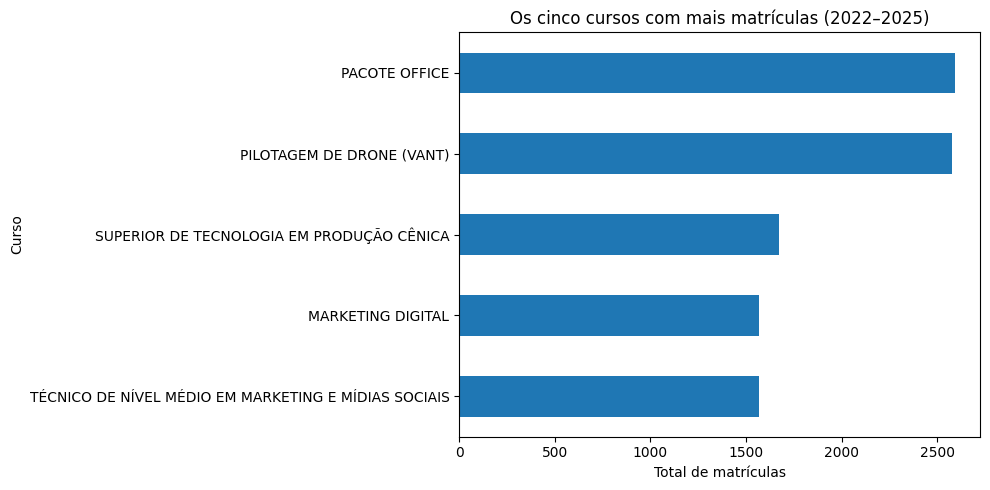

Interpretação: o curso com maior total é PACOTE OFFICE, com 2,594 matrículas.
Importância: conhecer os cursos com maior volume de matrículas ajuda a descrever como as matrículas estão distribuídas. Isso, sozinho, não prova a causa da procura.


In [ ]:
matriculas_curso_a7 = (
    dados_periodo.groupby("curso")["matriculas_turma"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

if not matriculas_curso_a7.empty:
    ax = matriculas_curso_a7.sort_values().plot(kind="barh", figsize=(10, 5))
    ax.set_title("Os cinco cursos com mais matrículas (2022–2025)")
    ax.set_xlabel("Total de matrículas")
    ax.set_ylabel("Curso")
    plt.tight_layout()
    plt.show()

    curso_top_a7 = matriculas_curso_a7.index[0]
    total_top_a7 = matriculas_curso_a7.iloc[0]
    print(f"Interpretação: o curso com maior total é {curso_top_a7}, com {total_top_a7:,.0f} matrículas.")
    print("Importância: conhecer os cursos com maior volume de matrículas ajuda a descrever como as matrículas estão distribuídas. Isso, sozinho, não prova a causa da procura.")
else:
    print("Não há dados de cursos para montar o gráfico.")

## 17. Gráfico de linhas — evolução anual

**Pergunta:** como o total de matrículas mudou de 2022 a 2025?

Escolhi um gráfico de linhas porque ele ajuda a acompanhar mudanças ao longo do tempo. O ano é obtido a partir da data de início das turmas.

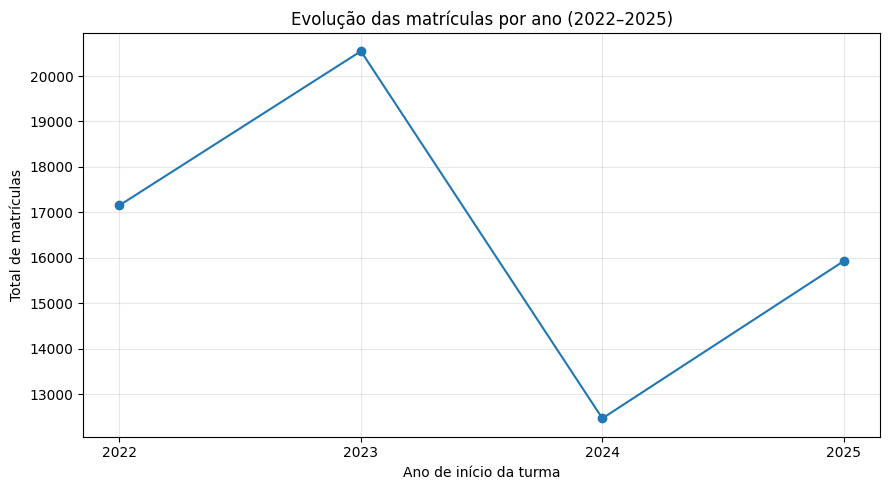

Interpretação: entre 2022 e 2025, o total variou em -1,227 matrículas (-7.15%).


In [ ]:
matriculas_ano_a7 = (
    dados_periodo.groupby("ano")["matriculas_turma"]
    .sum()
    .sort_index()
)

if not matriculas_ano_a7.empty:
    ax = matriculas_ano_a7.plot(kind="line", marker="o", figsize=(9, 5))
    ax.set_title("Evolução das matrículas por ano (2022–2025)")
    ax.set_xlabel("Ano de início da turma")
    ax.set_ylabel("Total de matrículas")
    ax.set_xticks(matriculas_ano_a7.index)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    if len(matriculas_ano_a7) >= 2:
        ano_inicial_a7, ano_final_a7 = matriculas_ano_a7.index[0], matriculas_ano_a7.index[-1]
        valor_inicial_a7, valor_final_a7 = matriculas_ano_a7.iloc[0], matriculas_ano_a7.iloc[-1]
        diferenca_a7 = valor_final_a7 - valor_inicial_a7
        if valor_inicial_a7 != 0:
            variacao_a7 = diferenca_a7 / valor_inicial_a7 * 100
            print(f"Interpretação: entre {ano_inicial_a7} e {ano_final_a7}, o total variou em {diferenca_a7:,.0f} matrículas ({variacao_a7:.2f}%).")
        else:
            print(f"Interpretação: o total passou de {valor_inicial_a7:,.0f} em {ano_inicial_a7} para {valor_final_a7:,.0f} em {ano_final_a7}.".replace(",", "."))
    else:
        print("Há dados de apenas um ano; ainda não é possível comparar a evolução.")
else:
    print("Não há dados anuais disponíveis para montar o gráfico.")

## 18. Histograma — distribuição das matrículas por registro

**Pergunta:** a quantidade de matrículas por registro está concentrada em uma faixa ou apresenta grande dispersão?

Escolhi o histograma porque ele mostra como os valores numéricos se distribuem. Cada observação corresponde a um registro de turma na base; valores ausentes não entram no gráfico.

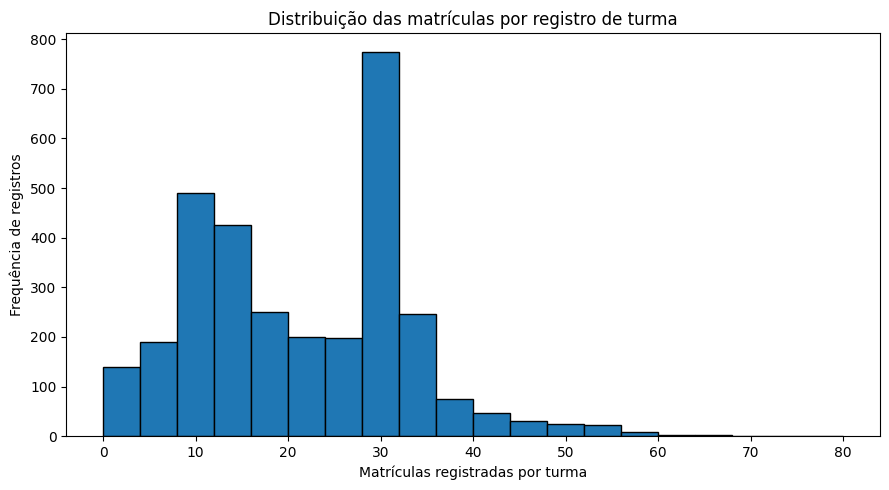

Menor valor: 0
Mediana: 21,0
Maior valor: 80
Interpretação: observe onde as barras ficam mais altas e se existe uma cauda de registros com valores elevados. A distribuição, sozinha, não explica por que as turmas têm tamanhos diferentes.


In [ ]:
matriculas_validas_a7 = pd.to_numeric(
    dados_periodo["matriculas_turma"], errors="coerce"
).dropna()

if not matriculas_validas_a7.empty:
    ax = matriculas_validas_a7.plot(kind="hist", bins=20, figsize=(9, 5), edgecolor="black")
    ax.set_title("Distribuição das matrículas por registro de turma")
    ax.set_xlabel("Matrículas registradas por turma")
    ax.set_ylabel("Frequência de registros")
    plt.tight_layout()
    plt.show()

    print(f"Menor valor: {matriculas_validas_a7.min():,.0f}".replace(",", "."))
    print(f"Mediana: {matriculas_validas_a7.median():,.1f}".replace(",", "X").replace(".", ",").replace("X", "."))
    print(f"Maior valor: {matriculas_validas_a7.max():,.0f}".replace(",", "."))
    print("Interpretação: observe onde as barras ficam mais altas e se existe uma cauda de registros com valores elevados. A distribuição, sozinha, não explica por que as turmas têm tamanhos diferentes.")
else:
    print("Não há valores numéricos de matrículas para montar o histograma.")

## 19. Planejamento do Dashboard

A tabela abaixo organiza a primeira versão do Dashboard para a Home do Login System. A ideia é apresentar primeiro os indicadores, depois os gráficos e, por fim, o insight e a conclusão.

In [ ]:
planejamento_dashboard_a7 = pd.DataFrame([
    {
        "Elemento": "Problema",
        "Conteúdo": "Entender como turmas, vagas e matrículas se distribuem e mudam entre escolas, cursos e modalidades."
    },
    {
        "Elemento": "Público",
        "Conteúdo": "Gestores, equipes das Escolas do Futuro e pessoas interessadas na oferta de cursos."
    },
    {
        "Elemento": "Indicador 1",
        "Conteúdo": f"Total de turmas únicas: {total_turmas_a7:,}".replace(",", ".")
    },
    {
        "Elemento": "Indicador 2",
        "Conteúdo": f"Total de vagas: {total_vagas_a7:,.0f}".replace(",", ".")
    },
    {
        "Elemento": "Indicador 3",
        "Conteúdo": f"Total de matrículas: {total_matriculas_a7:,.0f}".replace(",", ".")
    },
    {
        "Elemento": "Indicador 4",
        "Conteúdo": f"Taxa geral de ocupação: {taxa_ocupacao_a7:.2f}%".replace(".", ",")
    },
    {
        "Elemento": "Gráfico 1",
        "Conteúdo": "Barras dos cinco cursos com mais matrículas; responde quais cursos concentram mais matrículas."
    },
    {
        "Elemento": "Gráfico 2",
        "Conteúdo": "Linha de matrículas por ano; responde como o total mudou de 2022 a 2025."
    },
    {
        "Elemento": "Gráfico 3",
        "Conteúdo": "Histograma das matrículas por registro; responde como os valores se distribuem."
    },
    {
        "Elemento": "Insight principal",
        "Conteúdo": f"O curso com maior total de matrículas é {curso_lider_a7.index[0]}." if len(curso_lider_a7) else "Não foi possível identificar o curso líder."
    },
    {
        "Elemento": "Conclusão",
        "Conteúdo": "Os indicadores e gráficos permitem visualizar a distribuição das matrículas e comparar a oferta com as vagas. As causas das diferenças exigem outras informações."
    },
    {
        "Elemento": "Recomendação",
        "Conteúdo": "Acompanhar a taxa de ocupação por curso, escola e modalidade e investigar os grupos com ocupação baixa ou muito alta."
    }
])
display(planejamento_dashboard_a7)

,Elemento,Conteúdo
0,Problema,"Entender como turmas, vagas e matrículas se di..."
1,Público,"Gestores, equipes das Escolas do Futuro e pess..."
2,Indicador 1,Total de turmas únicas: 1.908
3,Indicador 2,Total de vagas: 70.543
4,Indicador 3,Total de matrículas: 66.092
5,Indicador 4,"Taxa geral de ocupação: 93,69%"
6,Gráfico 1,Barras dos cinco cursos com mais matrículas; r...
7,Gráfico 2,Linha de matrículas por ano; responde como o t...
8,Gráfico 3,Histograma das matrículas por registro; respon...
9,Insight principal,O curso com maior total de matrículas é PACOTE...


### Esboço da tela

1. **Cabeçalho:** Dashboard das Escolas do Futuro de Goiás — período 2022 a 2025.
2. **Primeira linha:** cards com total de turmas, vagas, matrículas e taxa de ocupação.
3. **Área principal:** gráfico de barras dos cinco cursos com mais matrículas.
4. **Área secundária:** linha da evolução anual e histograma da distribuição.
5. **Rodapé:** insight principal, conclusão e recomendação.

O Login System deve continuar responsável por login, autenticação e controle de acesso. O Dashboard apresenta os dados públicos da análise; os dados de autenticação não devem ser usados como base analítica.

## 20. Pergunta norteadora — um bom gráfico explica ou apenas mostra?

**1. Qual pergunta a visualização pretende responder?**  
O gráfico de barras pretende mostrar quais cursos concentram mais matrículas no período de 2022 a 2025.

**2. Qual informação ela apresenta?**  
Apresenta o total de matrículas registrado para cada um dos cinco cursos com maiores valores.

**3. Qual insight pode ser extraído?**  
O curso que aparece no topo possui o maior total de matrículas da base no período analisado. O nome e o valor são impressos automaticamente pela célula do gráfico.

**4. Por que esse tipo de gráfico foi escolhido?**  
Porque barras facilitam a comparação entre categorias e permitem identificar rapidamente os maiores valores.

**5. O que poderia ser melhorado?**  
Podemos incluir o valor no final de cada barra, usar filtros por escola ou ano e apresentar uma explicação sobre o período e a origem dos dados.

**Conclusão da Aula 7:** um bom gráfico não deve apenas mostrar valores. Ele precisa responder a uma pergunta, destacar uma evidência e ajudar o público a entender o problema. Os resultados também precisam ser apresentados com suas limitações.

In [ ]:
# Exportar o planejamento do Dashboard para consulta ou entrega
planejamento_dashboard_a7.to_csv(
    "planejamento_dashboard_aula7.csv",
    index=False,
    encoding="utf-8-sig"
)
indicadores_aula7.to_csv(
    "indicadores_dashboard_aula7.csv",
    index=False,
    encoding="utf-8-sig"
)
print("Arquivos gerados:")
print("- planejamento_dashboard_aula7.csv")
print("- indicadores_dashboard_aula7.csv")
# No Google Colab, se quiser baixar os arquivos, descomente:
# from google.colab import files
# files.download("planejamento_dashboard_aula7.csv")
# files.download("indicadores_dashboard_aula7.csv")